## **Machine learning-CS1461 Project**

**Team Members** :

1.  Razan alfurih
2.  Rand alrabiah

1.   Tala almugren
2.   Raneem Alsulami

**Section** : 372

In [ ]:
# Import libraries
from google.colab import files
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import resample

In [ ]:
# Load dataset
uploaded = files.upload()

with zipfile.ZipFile("spambase.zip", "r") as zip_ref:
    zip_ref.extractall("spambase_data")

os.listdir("spambase_data")
data = pd.read_csv("spambase_data/spambase.data", header=None)

# first 5 rows
data.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


We uploaded the dataset and extracted it from the ZIP file to access the data.

In [ ]:
columns = []

with open("spambase_data/spambase.names", "r") as f:
    content = f.read()

import re

found_names = re.findall(r'^([\w\_!$#\[\]\(\);]+):', content, re.MULTILINE)

columns = found_names + ["spam"]

df = data.copy()

df.columns = columns

print("Dataset shape:")
print(df.shape)

print("\nClass distribution:")
print(df["spam"].value_counts())

print("\nClass percentage:")
print(df["spam"].value_counts(normalize=True) * 100)

print("\nMissing values:")
print(df.isnull().sum().sum())

df.head()

Dataset shape:
(4601, 58)

Class distribution:
spam
0    2788
1    1813
Name: count, dtype: int64

Class percentage:
spam
0    60.595523
1    39.404477
Name: proportion, dtype: float64

Missing values:
0


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


We loaded the dataset

In [ ]:
print("Class Split:")
print("0 = Not Spam email")
print("1 = Spam email")


print("\nClass Distribution:")
print(df["spam"].value_counts())


X = df.drop("spam", axis=1)

y = df["spam"]


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Train size:", X_train.shape)

print("Validation size:", X_val.shape)

print("Test size:", X_test.shape)

Class Split:
0 = Not Spam email
1 = Spam email

Class Distribution:
spam
0    2788
1    1813
Name: count, dtype: int64
Train size: (3220, 57)
Validation size: (690, 57)
Test size: (691, 57)


The dataset has two classes: 1 spam emails and 0 not spam emails. The dataset was divided into features (X) and target variable (y). the data was split into training, validation, and testing sets.

# **1- Decision Tree without normalization**

Decision Tree without normalization
Train Accuracy: 99.969
Test Accuracy: 87.844

Confusion Matrix:
Classification Report Without Normalization:
              precision    recall  f1-score   support

    Not Spam       0.91      0.88      0.90       419
        Spam       0.83      0.87      0.85       272

    accuracy                           0.88       691
   macro avg       0.87      0.88      0.87       691
weighted avg       0.88      0.88      0.88       691



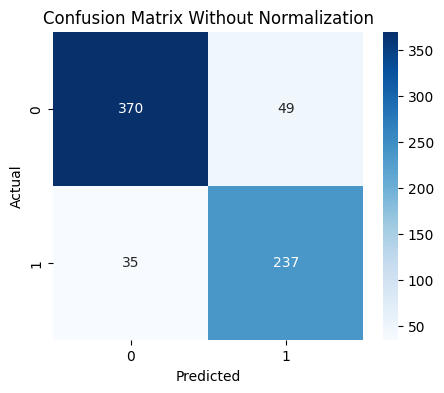

In [ ]:
modelWithoutNorm = DecisionTreeClassifier(random_state=42)

modelWithoutNorm.fit(X_train, y_train)

y_train_pred = modelWithoutNorm.predict(X_train)
y_pred = modelWithoutNorm.predict(X_test)

train_acc_no_norm = accuracy_score(y_train, y_train_pred)
acc_no_norm = accuracy_score(y_test, y_pred)

print("Decision Tree without normalization")
print("Train Accuracy:", f"{train_acc_no_norm * 100:.3f}")
print("Test Accuracy:", f"{acc_no_norm * 100:.3f}")

confMatWON = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")

print("Classification Report Without Normalization:")
print(classification_report(y_test, y_pred, target_names=["Not Spam", "Spam"]))


plt.figure(figsize=(5,4))

sns.heatmap(confMatWON, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Without Normalization")


plt.show()

We trained the Decision Tree model without normalization to create an initial model for comparison.Then we check performance using accuracy and confusion matrix.

# **2- Decision Tree with normalization**

Decision Tree with normalization
Train Accuracy: 99.969
Test Accuracy: 87.844

Confusion Matrix:
Classification Report With Normalization:
              precision    recall  f1-score   support

    Not Spam       0.91      0.88      0.90       419
        Spam       0.83      0.87      0.85       272

    accuracy                           0.88       691
   macro avg       0.87      0.88      0.87       691
weighted avg       0.88      0.88      0.88       691



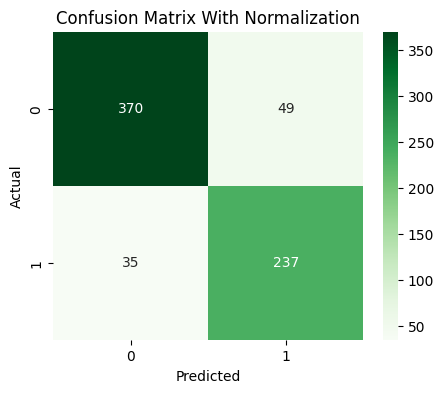

In [ ]:
scaler = MinMaxScaler()

X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)
X_val_norm = scaler.transform(X_val)

modelWithNorm = DecisionTreeClassifier(random_state=42)

modelWithNorm.fit(X_train_norm, y_train)

y_train_pred_norm = modelWithNorm.predict(X_train_norm)
y_pred_norm = modelWithNorm.predict(X_test_norm)

train_acc_norm = accuracy_score(y_train, y_train_pred_norm)
acc_norm = accuracy_score(y_test, y_pred_norm)

print("Decision Tree with normalization")
print("Train Accuracy:", f"{train_acc_norm * 100:.3f}")
print("Test Accuracy:", f"{acc_norm * 100:.3f}")

confMatWN = confusion_matrix(y_test, y_pred_norm)
print("\nConfusion Matrix:")

print("Classification Report With Normalization:")
print(classification_report(y_test, y_pred_norm, target_names=["Not Spam", "Spam"]))


plt.figure(figsize=(5,4))

sns.heatmap(confMatWN, annot=True, fmt='d', cmap='Greens')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix With Normalization")

plt.show()

We used MinMaxScaler for normalization and we trained the Decision Tree model again to compare the results before and after normalization.

# **3- Comparison Without and With Normalization**

In [ ]:
comparison_norm = pd.DataFrame({
    "Case": ["Without Normalization", "With Normalization"],
    "Train Accuracy": [
        f"{train_acc_no_norm * 100:.3f}",
        f"{train_acc_norm * 100:.3f}"
    ],
    "Test Accuracy": [
        f"{acc_no_norm * 100:.3f}",
        f"{acc_norm * 100:.3f}"
    ]
})

comparison_norm

,Case,Train Accuracy,Test Accuracy
0,Without Normalization,99.969,87.844
1,With Normalization,99.969,87.844


The results from both models were compared to evaluate the effect of normalization on the Decision Tree classifier.

# **4- Without addressing the overfitting**

Tree depth: 32
Number of leaves: 214
Decision Tree Before Addressing Overfitting
Train Accuracy: 99.969
Test Accuracy: 87.844

Confusion Matrix:
Classification Report Before Handling Overfitting:
              precision    recall  f1-score   support

    Not Spam       0.91      0.88      0.90       419
        Spam       0.83      0.87      0.85       272

    accuracy                           0.88       691
   macro avg       0.87      0.88      0.87       691
weighted avg       0.88      0.88      0.88       691



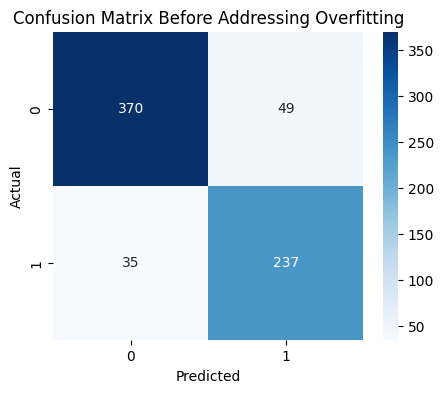

In [ ]:
modelBeforeOverfit = DecisionTreeClassifier(random_state=42)

modelBeforeOverfit.fit(X_train, y_train)

print("Tree depth:", modelBeforeOverfit.get_depth())
print("Number of leaves:", modelBeforeOverfit.get_n_leaves())

y_train_pred_before = modelBeforeOverfit.predict(X_train)
y_test_pred_before = modelBeforeOverfit.predict(X_test)

train_acc_before_overfit = accuracy_score(y_train, y_train_pred_before)
test_acc_before_overfit = accuracy_score(y_test, y_test_pred_before)

print("Decision Tree Before Addressing Overfitting")
print("Train Accuracy:", f"{train_acc_before_overfit * 100:.3f}")
print("Test Accuracy:", f"{test_acc_before_overfit * 100:.3f}")

confMatBeforeOverfit = confusion_matrix(y_test, y_test_pred_before)
print("\nConfusion Matrix:")

print("Classification Report Before Handling Overfitting:")
print(classification_report(y_test, y_test_pred_before, target_names=["Not Spam", "Spam"]))


plt.figure(figsize=(5,4))

sns.heatmap(confMatBeforeOverfit, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Before Addressing Overfitting")

plt.show()

This model was trained without limiting the depth, which may cause overfitting.

In [ ]:
# Test different max_depth values using validation data

depths = range(1, 21)

train_scores = []
val_scores = []

for d in depths:
    modelDepth = DecisionTreeClassifier(max_depth=d, random_state=42)
    modelDepth.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, modelDepth.predict(X_train))
    val_acc = accuracy_score(y_val, modelDepth.predict(X_val))

    train_scores.append(train_acc)
    val_scores.append(val_acc)

depth_results = pd.DataFrame({
    "Depth": list(depths),
    "Train Accuracy": [f"{score * 100:.3f}" for score in train_scores],
    "Validation Accuracy": [f"{score * 100:.3f}" for score in val_scores]
})

depth_results


,Depth,Train Accuracy,Validation Accuracy
0,1,79.658,79.130
1,2,86.615,86.812
2,3,89.752,88.841
3,4,91.677,90.145
4,5,92.391,91.159
5,6,93.137,90.145
6,7,94.130,91.304
7,8,95.186,91.739
8,9,95.807,90.870
9,10,96.708,92.464


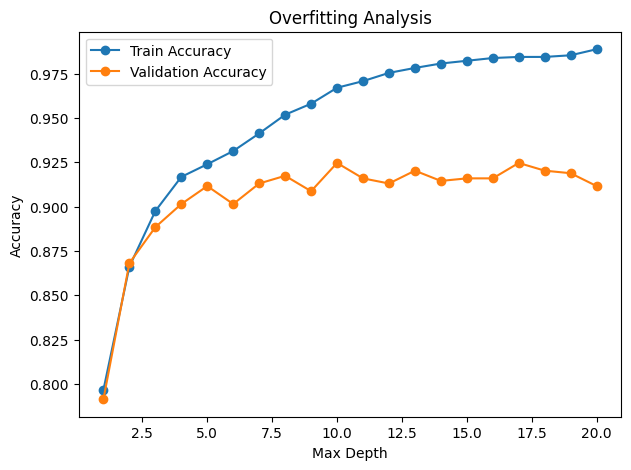

In [ ]:
# Plot training and validation accuracy

plt.figure(figsize=(7,5))

plt.plot(depths, train_scores, marker='o', label='Train Accuracy')
plt.plot(depths, val_scores, marker='o', label='Validation Accuracy')

plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Analysis")
plt.legend()
plt.show()

**Choose Best Depth**


In [ ]:
# Select the best max_depth based on highest validation accuracy

best_depth = depths[val_scores.index(max(val_scores))]

print("Best max_depth:", best_depth)
print("Best Validation Accuracy:", f"{max(val_scores) * 100:.3f}")

Best max_depth: 10
Best Validation Accuracy: 0.9246376811594202


We tested different max_depth values and used validation accuracy to choose the best one.

# **5- With addressing overfitting**

Decision Tree After Addressing Overfitting
Best max_depth: 10
Train Accuracy: 96.708
Test Accuracy: 91.027

Confusion Matrix:
Classification Report After Handling Overfitting:
              precision    recall  f1-score   support

    Not Spam       0.91      0.95      0.93       419
        Spam       0.91      0.86      0.88       272

    accuracy                           0.91       691
   macro avg       0.91      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691



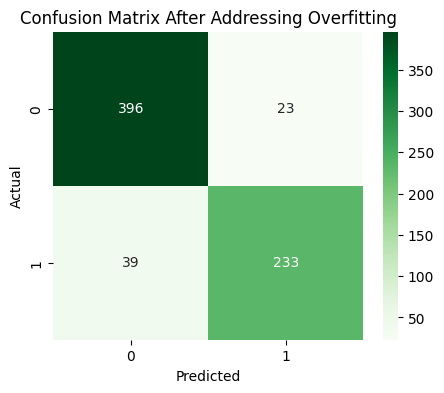

In [ ]:

modelAfterOverfit = DecisionTreeClassifier(max_depth=best_depth, random_state=42)

modelAfterOverfit.fit(X_train, y_train)

y_train_pred_after = modelAfterOverfit.predict(X_train)
y_test_pred_after = modelAfterOverfit.predict(X_test)

train_acc_after_overfit = accuracy_score(y_train, y_train_pred_after)
test_acc_after_overfit = accuracy_score(y_test, y_test_pred_after)

print("Decision Tree After Addressing Overfitting")
print("Best max_depth:", best_depth)
print("Train Accuracy:", f"{train_acc_after_overfit * 100:.3f}")
print("Test Accuracy:", f"{test_acc_after_overfit * 100:.3f}")

confMatAfterOverfit = confusion_matrix(y_test, y_test_pred_after)
print("\nConfusion Matrix:")

print("Classification Report After Handling Overfitting:")
print(classification_report(y_test,y_test_pred_after, target_names=["Not Spam", "Spam"]))

plt.figure(figsize=(5,4))

sns.heatmap(confMatAfterOverfit, annot=True, fmt='d', cmap='Greens')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix After Addressing Overfitting")

plt.show()

The final model was trained using the best depth to improve generalization.

# **6- Comparison before and after addressing overfitting**

In [ ]:
comparison_overfit = pd.DataFrame({
    "Case": ["Before Addressing Overfitting", "After Addressing Overfitting"],
    "Train Accuracy": [
        f"{train_acc_before_overfit * 100:.3f}",
        f"{train_acc_after_overfit * 100:.3f}"
    ],
    "Test Accuracy": [
        f"{test_acc_before_overfit * 100:.3f}",
        f"{test_acc_after_overfit * 100:.3f}"
    ]
})

comparison_overfit

,Case,Train Accuracy,Test Accuracy
0,Before Addressing Overfitting,99.969,87.844
1,After Addressing Overfitting,96.708,91.027


# **7- Before balancing**

Decision Tree Before Balancing
Train Accuracy: 96.708
Test Accuracy: 91.027
Classification Report Before Balancing:
              precision    recall  f1-score   support

    Not Spam       0.91      0.95      0.93       419
        Spam       0.91      0.86      0.88       272

    accuracy                           0.91       691
   macro avg       0.91      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691



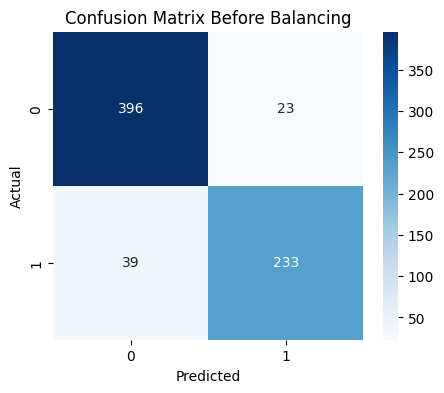

In [ ]:
model_bias = DecisionTreeClassifier(max_depth=best_depth, random_state=42)

model_bias.fit(X_train, y_train)

y_bias_train = model_bias.predict(X_train)
y_bias_test = model_bias.predict(X_test)

train_acc_bal_before = accuracy_score(y_train, y_bias_train)
test_acc_bal_before = accuracy_score(y_test, y_bias_test)

print("Decision Tree Before Balancing")
print("Train Accuracy:", f"{train_acc_bal_before * 100:.3f}")
print("Test Accuracy:", f"{test_acc_bal_before * 100:.3f}")


confMatBiasBefore = confusion_matrix(y_test, y_bias_test)

print("Classification Report Before Balancing:")
print(classification_report(y_test,y_bias_test, target_names=["Not Spam", "Spam"]))


plt.figure(figsize=(5,4))
sns.heatmap(confMatBiasBefore, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Before Balancing")
plt.show()

The model was trained on the imbalanced dataset.

# **8- Balancing**

In [ ]:
train_data = pd.concat([X_train, y_train], axis=1)

spam = train_data[train_data["spam"] == 1]
not_spam = train_data[train_data["spam"] == 0]

spam_up = resample(
    spam,
    replace=True,
    n_samples=len(not_spam),
    random_state=42
)

balanced = pd.concat([not_spam, spam_up])
balanced = balanced.sample(frac=1, random_state=42)

X_bal = balanced.drop("spam", axis=1)
y_bal = balanced["spam"]

print("Before Balancing:")
print(train_data["spam"].value_counts())

print("\nAfter Balancing:")
print(y_bal.value_counts())

Before Balancing:
spam
0    1951
1    1269
Name: count, dtype: int64

After Balancing:
spam
0    1951
1    1951
Name: count, dtype: int64


We balanced the dataset by oversampling the minority class.

# **9- After Balancing**

Decision Tree After Balancing
Train Accuracy: 96.925
Test Accuracy: 90.593
              precision    recall  f1-score   support

    Not Spam       0.92      0.93      0.92       419
        Spam       0.88      0.88      0.88       272

    accuracy                           0.91       691
   macro avg       0.90      0.90      0.90       691
weighted avg       0.91      0.91      0.91       691

Classification Report After Balancing:


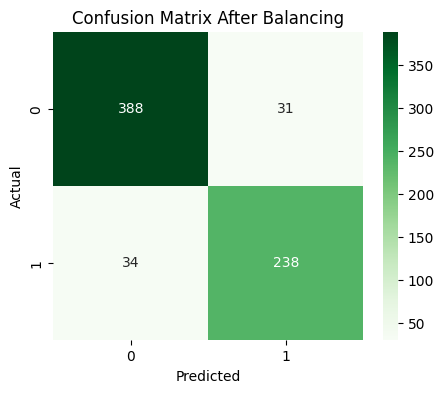

In [ ]:
modelBalanced = DecisionTreeClassifier(max_depth=best_depth, random_state=42)

modelBalanced.fit(X_bal, y_bal)

y_bal_train_pred = modelBalanced.predict(X_bal)
y_bal_test_pred = modelBalanced.predict(X_test)

train_acc_bal_after = accuracy_score(y_bal, y_bal_train_pred)
test_acc_bal_after = accuracy_score(y_test, y_bal_test_pred)

print("Decision Tree After Balancing")
print("Train Accuracy:", f"{train_acc_bal_after * 100:.3f}")
print("Test Accuracy:", f"{test_acc_bal_after * 100:.3f}")


confMatBalAfter = confusion_matrix(y_test, y_bal_test_pred)

print("Classification Report After Balancing:")
print(classification_report(y_test, y_bal_test_pred, target_names=["Not Spam", "Spam"]))



plt.figure(figsize=(5,4))
sns.heatmap(confMatBalAfter, annot=True, fmt='d', cmap='Greens')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix After Balancing")
plt.show()

The model was retrained on the balanced dataset.

# **10- compare before and after balancing**

In [ ]:
comparison_balance = pd.DataFrame({
    "Case": ["Before Balancing", "After Balancing"],
    "Train Accuracy": [
        f"{train_acc_bal_before * 100:.3f}",
        f"{train_acc_bal_after * 100:.3f}"
    ],
    "Test Accuracy": [
        f"{test_acc_bal_before * 100:.3f}",
        f"{test_acc_bal_after * 100:.3f}"
    ]
})

comparison_balance

,Case,Train Accuracy,Test Accuracy
0,Before Balancing,96.708,91.027
1,After Balancing,96.925,90.593


# **11- Visualization**

**Normalization**

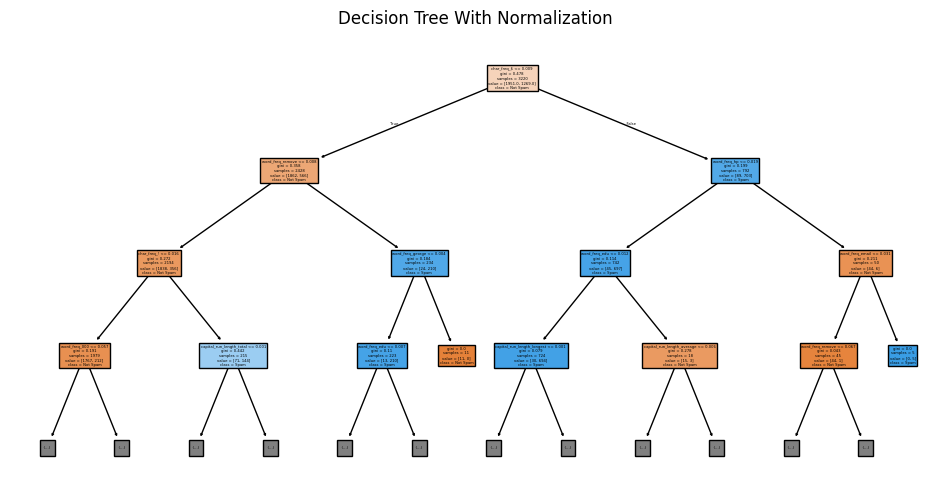

In [ ]:
plt.figure(figsize=(12,6))
plot_tree(modelWithNorm, max_depth=3, filled=True, class_names=["Not Spam", "Spam"],feature_names=list(X.columns))
plt.title("Decision Tree With Normalization")
plt.show()

**Overfitting**

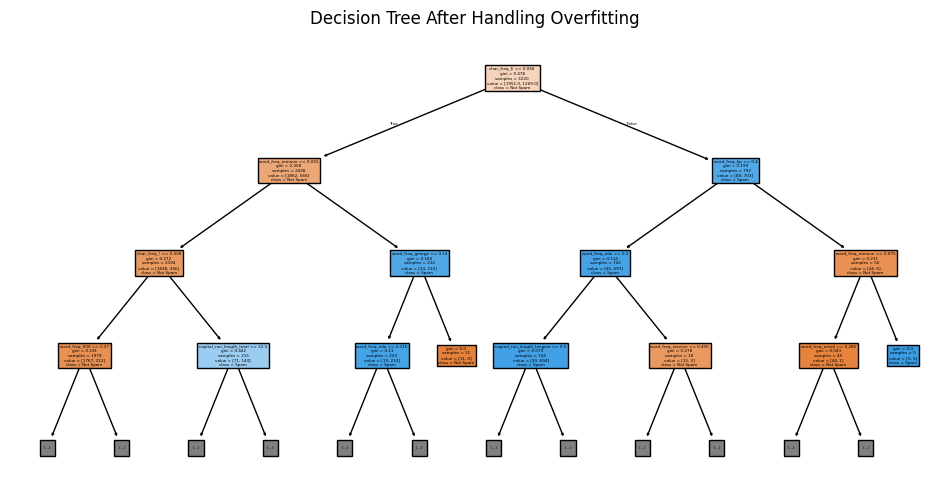

In [ ]:
plt.figure(figsize=(12,6))
plot_tree(modelAfterOverfit, max_depth=3, filled=True, class_names=["Not Spam", "Spam"],feature_names=list(X.columns))
plt.title("Decision Tree After Handling Overfitting")
plt.show()

**Balancing**

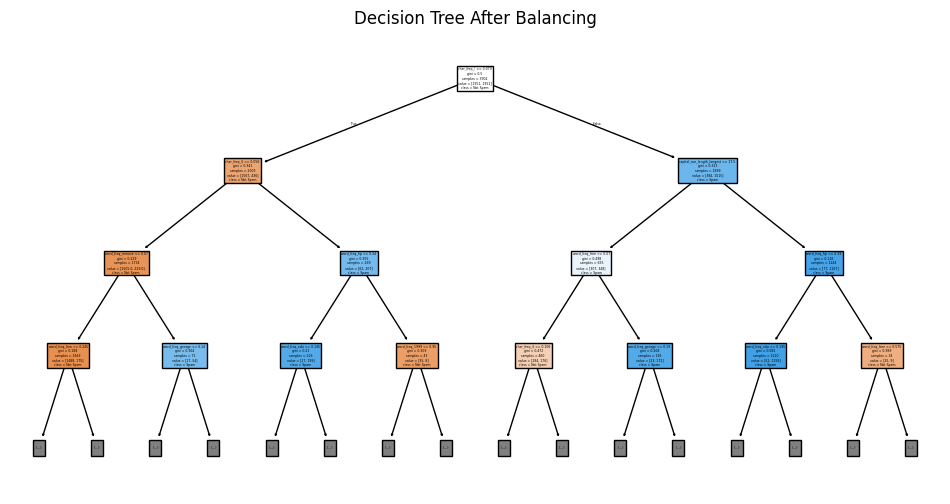

In [ ]:
plt.figure(figsize=(12,6))
plot_tree(modelBalanced, max_depth=3, filled=True, class_names=["Not Spam", "Spam"],feature_names=list(X.columns))
plt.title("Decision Tree After Balancing")
plt.show()

# **12- Rules**

**Normalization**


In [ ]:
rules_norm = export_text(modelWithNorm, feature_names=list(X.columns))
print("Rules With Normalization:")
print(rules_norm)

Rules With Normalization:
|--- char_freq_$ <= 0.01
|   |--- word_freq_remove <= 0.01
|   |   |--- char_freq_! <= 0.02
|   |   |   |--- word_freq_000 <= 0.06
|   |   |   |   |--- word_freq_free <= 0.00
|   |   |   |   |   |--- word_freq_credit <= 0.02
|   |   |   |   |   |   |--- word_freq_our <= 0.08
|   |   |   |   |   |   |   |--- capital_run_length_average <= 0.02
|   |   |   |   |   |   |   |   |--- word_freq_money <= 0.13
|   |   |   |   |   |   |   |   |   |--- word_freq_650 <= 0.78
|   |   |   |   |   |   |   |   |   |   |--- word_freq_font <= 0.01
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 22
|   |   |   |   |   |   |   |   |   |   |--- word_freq_font >  0.01
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |   |   |   |   |   |--- word_freq_650 >  0.78
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |--- word_freq_money >  0.13
|   |   |   |   |   |   |   |   |   |

**Overfitting**

In [ ]:
rules_overfit = export_text(modelAfterOverfit, feature_names=list(X.columns))
print("Rules After Handling Overfitting:")
print(rules_overfit)

Rules After Handling Overfitting:
|--- char_freq_$ <= 0.06
|   |--- word_freq_remove <= 0.05
|   |   |--- char_freq_! <= 0.51
|   |   |   |--- word_freq_000 <= 0.27
|   |   |   |   |--- word_freq_free <= 0.02
|   |   |   |   |   |--- word_freq_credit <= 0.43
|   |   |   |   |   |   |--- word_freq_our <= 0.72
|   |   |   |   |   |   |   |--- capital_run_length_average <= 19.71
|   |   |   |   |   |   |   |   |--- word_freq_money <= 1.29
|   |   |   |   |   |   |   |   |   |--- word_freq_650 <= 7.11
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |--- word_freq_650 >  7.11
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |--- word_freq_money >  1.29
|   |   |   |   |   |   |   |   |   |--- capital_run_length_longest <= 10.50
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |--- capital_run_length_longest >  10.50
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|  

**Balancing**


In [ ]:
rules_bal = export_text(modelBalanced, feature_names=list(X.columns))
print("Rules After Balancing:")
print(rules_bal)

Rules After Balancing:
|--- char_freq_! <= 0.08
|   |--- char_freq_$ <= 0.06
|   |   |--- word_freq_remove <= 0.07
|   |   |   |--- word_freq_free <= 0.24
|   |   |   |   |--- capital_run_length_longest <= 25.50
|   |   |   |   |   |--- word_freq_credit <= 10.44
|   |   |   |   |   |   |--- word_freq_will <= 6.07
|   |   |   |   |   |   |   |--- word_freq_font <= 0.10
|   |   |   |   |   |   |   |   |--- word_freq_money <= 1.16
|   |   |   |   |   |   |   |   |   |--- word_freq_over <= 1.61
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |--- word_freq_over >  1.61
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- word_freq_money >  1.16
|   |   |   |   |   |   |   |   |   |--- capital_run_length_longest <= 10.50
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |--- capital_run_length_longest >  10.50
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |